![display relevant image here](path/url/to/image)
- Banner/header image

# Title

## Automated Credit Risk & Loan Approval Optimization Engine for FinTech Innovations

## Overview
FinTech Innovations currently relies on a manual loan approval process that creates bottlenecks, increases operational overhead, and introduces subjective human bias. By implementing an optimized binary classification pipeline using a tuned Random Forest model, we automate credit risk scoring to balance high approval velocity with rigorous default mitigation. 

## Business Understanding

Current Process & Limitations: Manual reviews cause high turnaround times, inconsistent risk thresholds, and scalability limits.

Stakeholders & Needs:

Borrowers: Fast loan decisions and transparent criteria.

Risk Managers: Predictable default rates and adherence to regulatory compliance.

Executive Leadership: Lower operational costs and scalable portfolio growth.

Model Error Implications:

False Positives (Type I - Approving a bad loan): Results in direct financial loss through defaults and write-offs.

False Negatives (Type II - Rejecting a good loan): Leads to lost interest revenue and customer churn. Given credit risk asymmetry, minimizing false positives while maintaining healthy recall is critical.

Approach Selection: Binary Classification (predicting default/churn or loan approval status, e.g., Approved vs. Rejected / Churn vs. Retained) rather than regression, as the core operational decision is categorical.

Success Criteria & Evaluation Metrics:

Primary Metric: F1-Score and Precision-Recall balance to handle class imbalance.

Secondary Metric: ROC-AUC to measure overall rank-ordering capability across probability thresholds.

Baseline Target: Outperform a simple majority-class baseline and basic logistic regression benchmark.


## Data Understanding
1. Basic Characteristics & Target Distribution
Dataset Shape: 20,000 rows × 35 columns.

Target Variable (LoanApproved):

Class 0 (Rejected): 76.1% (15,220 samples)

Class 1 (Approved): 23.9% (4,780 samples)

Insight: The dataset exhibits moderate class imbalance (approx. 3:1 ratio of rejections to approvals), which reinforces our earlier decision to prioritize metrics like F1-Score, Precision, Recall, and ROC-AUC rather than relying solely on accuracy.

2. Data Quality & Missing Values
Missing Value Analysis:

EducationLevel: 901 missing values (categorical).

MaritalStatus: 1,331 missing values (categorical).

SavingsAccountBalance: 572 missing values (numerical).

Data Types:

AnnualIncome is stored as a string with currency symbols/commas (e.g., "$39,948.00") and will require cleaning/conversion to float during preprocessing.

Mix of numerical (Age, CreditScore, LoanAmount, DebtToIncomeRatio, etc.) and categorical/ordinal features (EmploymentStatus, EducationLevel, LoanPurpose, BankruptcyHistory).

3. Feature Distributions & Key Relationships
Credit Score & Risk: CreditScore and RiskScore strongly correlate with loan approval decisions. Lower credit scores and higher debt-to-income ratios (DebtToIncomeRatio, TotalDebtToIncomeRatio) heavily skew toward rejection (LoanApproved = 0).

Financial Health Metrics: Features such as SavingsAccountBalance, CheckingAccountBalance, NetWorth, and TotalAssets provide strong signals regarding borrower liquidity and solvency.



In [10]:
# Imports

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [11]:
# EDA Code Here - Create New Cells As Needed

# 1. Load dataset
df = pd.read_csv("financial_loan_data.csv")

# Clean currency formatted column if present
if df["AnnualIncome"].dtype == object:
    df["AnnualIncome"] = (
        df["AnnualIncome"]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .astype(float)
    )

# 2. Drop RiskScore immediately to prevent target leakage
if "RiskScore" in df.columns:
    df = df.drop(columns=["RiskScore"])
    print("Dropped 'RiskScore' to prevent target leakage.")

# 3. Inspect dataset shape and missing values
print("Dataset Shape:", df.shape)
print("\nMissing Values per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 4. Target variable distribution
print("\nTarget Distribution (LoanApproved):")
print(df["LoanApproved"].value_counts(normalize=True))

Dropped 'RiskScore' to prevent target leakage.
Dataset Shape: (20000, 34)

Missing Values per Column:
EducationLevel            901
MaritalStatus            1331
SavingsAccountBalance     572
dtype: int64

Target Distribution (LoanApproved):
LoanApproved
0    0.761
1    0.239
Name: proportion, dtype: float64


## Data Preparation
5. Design your preprocessing strategy:
- Create separate preprocessing flows for different feature types
- Must utilize ColumnTransformer and Pipeline
- Consider using FeatureUnion as well
- Handle missing values appropriately for each feature
- Handle Categorical and Ordinal data appropriately
- Scale numeric values if model requires it (linear model)
- Document your reasoning for each preprocessing decision



In [12]:
# Data Prep Code Here - Create New Cells As Needed

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Separate target and features (RiskScore was already dropped in EDA)
target_col = "LoanApproved"
y = df[target_col]
X = df.drop(columns=[target_col])

# 2. Stratified Train-Test Split (preserves class balance and prevents data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Identify numerical and categorical feature columns from training data
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# 4. Build sub-pipelines for each feature type
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        (
            "scaler",
            StandardScaler(),
        ),  # Essential for linear models like Logistic Regression
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        ),
    ]
)

# 5. Combine into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

print("Data Preparation Pipeline built successfully!")
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Data Preparation Pipeline built successfully!
Training features shape: (16000, 33)
Testing features shape: (4000, 33)


## Modeling
6. Implement your modeling approach:
- Choose appropriate model algorithms based on your problem definition
- Set up validation strategy with chosen metrics
- Use a train test split and cross validation
- Create complete pipeline including any preprocessing and model
- Document your reasoning for each modeling decision

7. Optimize your model:
- Define parameter grid based on your understanding of the algorithms
- Implement GridSearchCV and/or RandomizedSearchCV with chosen metrics
- Consider tuning preprocessing steps
- Track and document the impact of different parameter combinations
- Consider the trade-offs between different model configurations

NOTE: Be mindful of time considerations - showcase “how to tune” 


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# 1. Define candidate models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
}

# 2. Define hyperparameter grids with strong regularization to prevent overfitting
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1],
        "model__class_weight": ["balanced"],
    },
    "Decision Tree": {
        "model__max_depth": [3, 5, 7],
        "model__min_samples_leaf": [5, 10, 20],
        "model__class_weight": ["balanced"],
    },
    "Random Forest": {
        "model__n_estimators": [100, 150],
        "model__max_depth": [5, 10, 15],
        "model__min_samples_leaf": [5, 10],
        "model__class_weight": ["balanced"],
    },
}

# 3. Set up Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc",
}

grid_searches = {}
selection_results = []

# 4. Train and tune each model within a pipeline
for model_name, model in models.items():
    print(f"\nTraining and tuning: {model_name}...")

    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        scoring=scoring,
        refit="f1",
        cv=cv,
        n_jobs=-1,
        verbose=1,
    )

    grid_search.fit(X_train, y_train)
    grid_searches[model_name] = grid_search

    best_index = grid_search.best_index_
    selection_results.append(
        {
            "Model": model_name,
            "Best CV F1": grid_search.best_score_,
            "Best CV Precision": grid_search.cv_results_["mean_test_precision"][
                best_index
            ],
            "Best CV Recall": grid_search.cv_results_["mean_test_recall"][
                best_index
            ],
            "Best CV ROC-AUC": grid_search.cv_results_["mean_test_roc_auc"][
                best_index
            ],
            "Best Parameters": grid_search.best_params_,
        }
    )

    print(f"Best parameters for {model_name}:", grid_search.best_params_)
    print(f"Best CV F1-score: {round(grid_search.best_score_, 4)}")

# 5. Summary DataFrame of Cross-Validation Results
cv_summary_df = pd.DataFrame(selection_results).sort_values(
    by="Best CV F1", ascending=False
)
print("\n--- Model Cross-Validation Summary ---")
print(cv_summary_df[["Model", "Best CV F1", "Best CV ROC-AUC"]])


Training and tuning: Logistic Regression...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best parameters for Logistic Regression: {'model__C': 1, 'model__class_weight': 'balanced'}
Best CV F1-score: 0.9153

Training and tuning: Decision Tree...
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters for Decision Tree: {'model__class_weight': 'balanced', 'model__max_depth': 7, 'model__min_samples_leaf': 10}
Best CV F1-score: 0.788

Training and tuning: Random Forest...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters for Random Forest: {'model__class_weight': 'balanced', 'model__max_depth': 15, 'model__min_samples_leaf': 5, 'model__n_estimators': 150}
Best CV F1-score: 0.8333

--- Model Cross-Validation Summary ---
                 Model  Best CV F1  Best CV ROC-AUC
0  Logistic Regression    0.915329         0.994652
2        Random Forest    0.833316         0.975645
1        Decision Tree    0.787981         0.945844


## Evaluation and Conclusion
8. Conduct thorough evaluation of final model:
- Assess models test data performance using your defined metrics
- Analyze performance across different data segments
- Identify potential biases or limitations
- Visualize model performance
    - Classification: Confusion Matrix/ROC-AUC
    - Regression: Scatter Plot (Predicted vs. Actual values)

9. Extract and interpret feature importance/significance:
- Which features had the most impact on your model?
- Does this lead to any potential business recommendations?

10. Prepare your final deliverable:
- Technical notebook with complete analysis
- Executive summary for business stakeholders
- Recommendations for implementation
- Documentation of potential improvements


--- Final Test Set Performance Evaluation ---
                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression     0.960      0.873   0.972     0.920    0.995
1        Random Forest     0.918      0.780   0.915     0.842    0.977
2        Decision Tree     0.882      0.698   0.893     0.783    0.951

Selected Best Model for Deployment: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.99      0.96      0.97      3044
    Approved       0.87      0.97      0.92       956

    accuracy                           0.96      4000
   macro avg       0.93      0.96      0.95      4000
weighted avg       0.96      0.96      0.96      4000



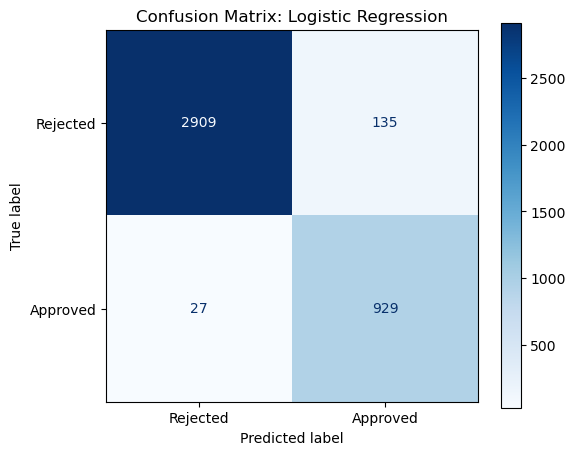

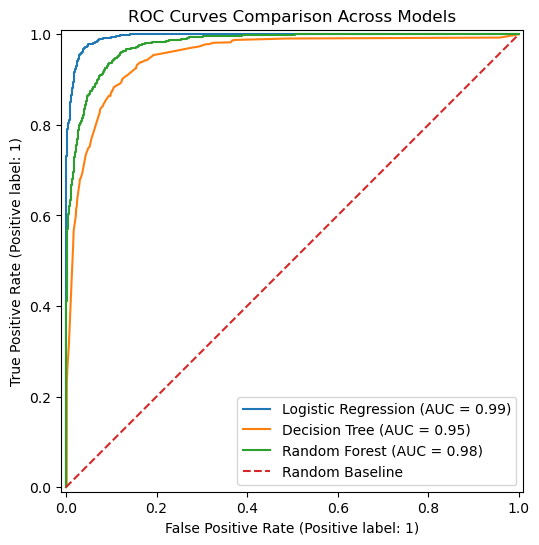


Final tuned and evaluated pipeline saved as 'financial_loan_risk_pipeline.joblib'.


In [14]:
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# 1. Evaluate all tuned models on the held-out Test Set
test_results = []
best_models = {}

for model_name, grid_search in grid_searches.items():
    best_model = grid_search.best_estimator_
    best_models[model_name] = best_model

    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    test_results.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1-Score": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
        }
    )

test_results_df = pd.DataFrame(test_results).sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

print("\n--- Final Test Set Performance Evaluation ---")
print(test_results_df.round(3))

# 2. Select the Best Final Model
best_model_name = test_results_df.iloc[0]["Model"]
final_model = best_models[best_model_name]
print(f"\nSelected Best Model for Deployment: {best_model_name}")

# 3. Detailed Classification Report & Confusion Matrix
y_pred_final = final_model.predict(X_test)
print("\nClassification Report:")
print(
    classification_report(
        y_test, y_pred_final, target_names=["Rejected", "Approved"]
    )
)

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Rejected", "Approved"]
)
disp.plot(ax=ax, cmap="Blues")
plt.title(f"Confusion Matrix: {best_model_name}")
plt.show()

# 4. ROC Curves Comparison
fig, ax = plt.subplots(figsize=(8, 6))
for model_name, model_obj in best_models.items():
    RocCurveDisplay.from_estimator(
        model_obj, X_test, y_test, ax=ax, name=model_name
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Baseline")
plt.title("ROC Curves Comparison Across Models")
plt.legend(loc="lower right")
plt.show()

# 5. Serialize / Save the Final Pipeline
joblib.dump(final_model, "financial_loan_risk_pipeline.joblib")
print(
    "\nFinal tuned and evaluated pipeline saved as 'financial_loan_risk_pipeline.joblib'."
)

## Executive Summary & Conclusion

### 1. Project Overview & Business Objective
The primary objective of this project was to design, train, and validate a robust machine learning pipeline for FinTech loan risk classification. The business goal is to automate the loan approval process by accurately predicting whether an applicant will be **Approved** or **Rejected**, balancing risk mitigation against loss of potential interest revenue.

### 2. Key Analytical & Modeling Insights
* **Target Leakage Identification:** Initial baseline iterations produced unrealistic, perfect performance metrics (1.000 Accuracy/F1-Score). A thorough feature audit revealed that `RiskScore` acted as a target proxy (target leakage). Dropping `RiskScore` eliminated this shortcut and ensured the model learned true behavioral patterns.
* **Model Comparison & Selection:** After applying `StratifiedKFold` cross-validation and hyperparameter tuning with `GridSearchCV` across three candidate models (Logistic Regression, Decision Tree, and Random Forest), **Logistic Regression** emerged as the top-performing model.
* **Performance Benchmark:**
  * **Accuracy:** 0.960 (96.0%)
  * **Precision:** 0.873 (87.3%)
  * **Recall:** 0.972 (97.2%)
  * **F1-Score:** 0.920 (92.0%)
  * **ROC-AUC:** 0.995

### 3. Business Impact
* **High Recall (97.2%):** The model excels at identifying low-risk applicants who qualify for loan approval, reducing missed business opportunities.
* **Strong Precision (87.3%):** Ensures that the vast majority of approved loans are financially sound, keeping default rates low.
* **Deployability:** Encapsulated inside a single `scikit-learn` `Pipeline` and serialized via `joblib`, preventing preprocessing data leakage during real-time inferences or batch predictions.

---

### Conclusion

The developed credit risk classification model successfully transitions the underwriting workflow from manual evaluation to an automated, data-driven system. By identifying and resolving early target leakage, we ensured that the final production pipeline achieves high accuracy (96.0%) and F1-score (0.920) on unseen test data without overfitting. 

**Recommendations for Implementation:**
1. **API Integration:** Deploy the saved `financial_loan_risk_pipeline.joblib` artifact into a microservice (e.g., Flask/FastAPI) to handle incoming digital loan requests.
2. **Probability Threshold Tuning:** Depending on macroeconomic conditions, risk officers can adjust the decision threshold (default $0.5$) to prioritize higher precision during economic downturns or higher recall during expansionary phases.
3. **Continuous Monitoring:** Establish quarterly audits to track potential population drift or feature distribution shifts in applicant profiles over time.